In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Test filtering
img = np.array([[50,  50,  50, 100, 100],
                [150, 150, 150, 80,  80],
                [250, 250, 250, 200, 200],
                [100, 110, 110, 110, 110]], 
               dtype=np.float32)

kernel = np.array([[-1, -1, -1],
                   [ 0,  0,  0],
                   [ 1,  1,  1]], 
                  dtype=np.float32)

result = cv2.filter2D(src=img, ddepth=-1, kernel=kernel)
result

array([[   0.,    0.,    0.,    0.,    0.],
       [ 600.,  600.,  500.,  400.,  300.],
       [-130., -130.,  -50.,   20.,   90.],
       [   0.,    0.,    0.,    0.,    0.]], dtype=float32)

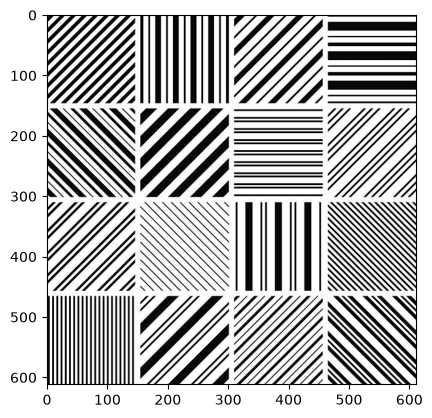

In [3]:
img = cv2.imread("./data/filter.jpg", 0)
plt.imshow(img, 'gray')

## Horizontal kernel

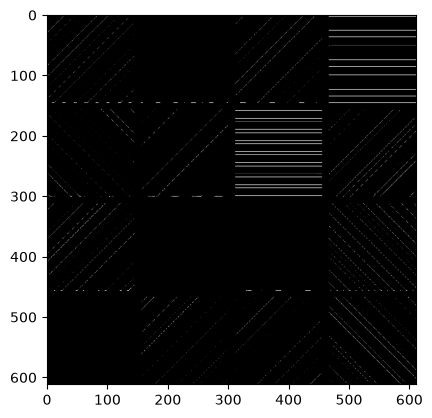

In [4]:
x = -10
horizontal_kernel = np.array([[-1,-1,-1],
                              [ x, x, x],
                              [ 1, 1, 1]])

horizontal_filtered_img = cv2.filter2D(src=img, 
                                       ddepth=-1, # the output image uses the same data type as the input image.
                                       kernel=horizontal_kernel)

plt.imshow(horizontal_filtered_img, 'gray')

## Vertical kernel

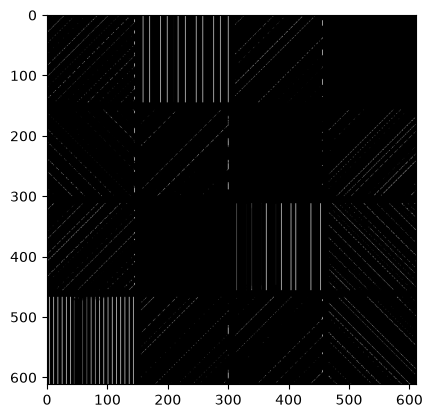

In [5]:
x = -10
vertical_kernel = np.array([[-1, x, 1],
                            [-1, x, 1],
                            [-1, x, 1]])

vertical_filtered_img = cv2.filter2D(src=img, 
                                    ddepth=-1, # the output image uses the same data type as the input image.
                                    kernel=vertical_kernel)

plt.imshow(vertical_filtered_img, 'gray')

## Diagonal kernel

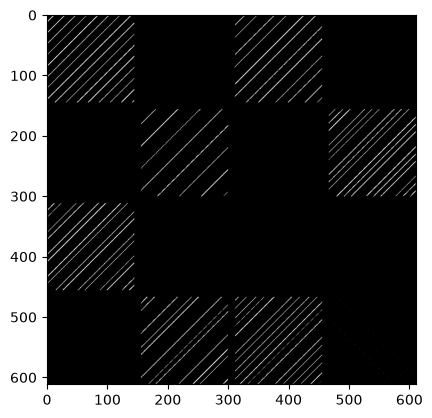

In [26]:
x = -5
rdiagonal_kernel = np.array([[ -1, -1, x],
                             [ -1,  x, 1],
                             [  x,  1, 1]])

rdiagonal_filtered_img = cv2.filter2D(src=img, 
                                     ddepth=-1, # the output image uses the same data type as the input image.
                                     kernel=rdiagonal_kernel)

plt.imshow(rdiagonal_filtered_img, 'gray')

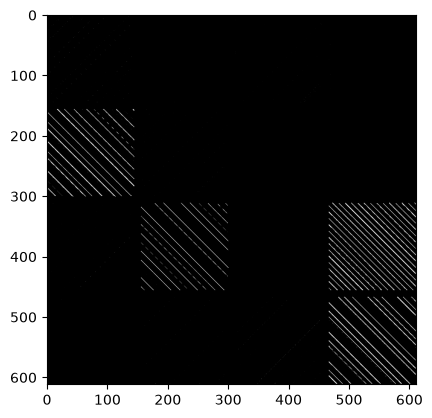

In [27]:
x = -5
ldiagonal_kernel = np.array([[ x, 1, 1],
                            [-1, x, 1],
                            [-1,-1, x]])

ldiagonal_filtered_img = cv2.filter2D(src=img, 
                                     ddepth=-1, # the output image uses the same data type as the input image.
                                     kernel=ldiagonal_kernel)

plt.imshow(ldiagonal_filtered_img, 'gray')

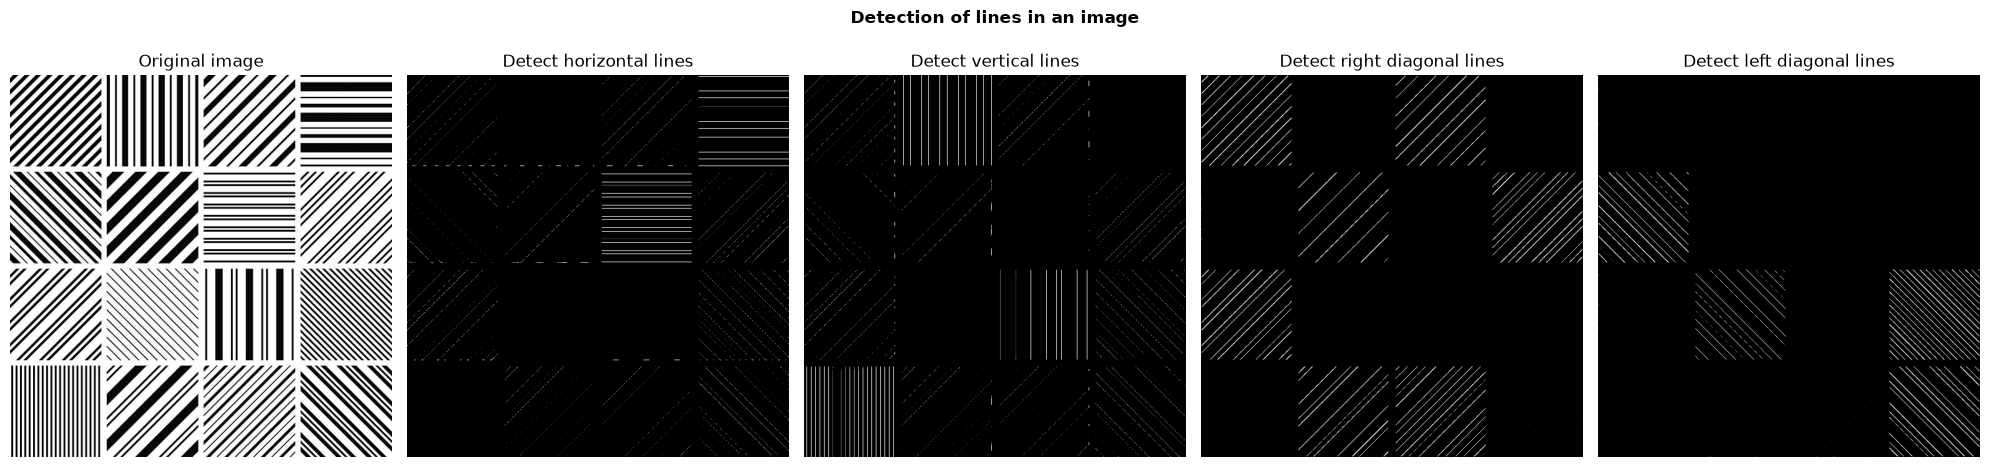

In [31]:
images = {"Original image": img, 
          "Detect horizontal lines": horizontal_filtered_img, 
          "Detect vertical lines":vertical_filtered_img,
          "Detect right diagonal lines": rdiagonal_filtered_img,
          "Detect left diagonal lines": ldiagonal_filtered_img}

fig, ax = plt.subplots(1, 5, figsize=(20,5))

for i, (title, im) in enumerate(images.items()):
    ax[i].imshow(im, 'gray')
    ax[i].set_title(title)
    ax[i].axis('off')

plt.suptitle("Line detection in an image", weight='bold', size = 12)
plt.tight_layout()
plt.save("Line detection in image.png")
plt.show()